<a href="https://colab.research.google.com/github/YasangaSTAT/Boston-Housing-Analysis/blob/main/Housing_Regression_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip install pandas numpy matplotlib seaborn scipy statsmodels scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
from google.colab import files

uploaded = files.upload()

Saving BostonHousing.csv to BostonHousing (1).csv


In [9]:
housing = pd.read_csv('BostonHousing.csv')

# Convert column names to uppercase to match your expected 'CRIM', 'ZN', etc.
housing.columns = housing.columns.str.upper()

housing.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [10]:
print("Dataset dimensions:", housing.shape)

print("\nColumn names:")
print(housing.columns.tolist())

print("\nDataset information:")
housing.info()

print("\nMissing values:")
print(housing.isnull().sum())

print("\nDuplicate observations:",
      housing.duplicated().sum())

housing.describe()

Dataset dimensions: (506, 14)

Column names:
['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       501 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB

Missing values:
CRIM       0
ZN         0
INDUS      0
CHAS  

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,501.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284341,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.705587,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.884000,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208000,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.625000,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [11]:
housing = housing.dropna(subset=['RM'])

In [12]:
print("Missing values in RM:",
      housing['RM'].isnull().sum())

print("Updated dataset dimensions:",
      housing.shape)

Missing values in RM: 0
Updated dataset dimensions: (501, 14)


In [13]:
descriptive_stats = pd.DataFrame({
    'Mean': housing.mean(),
    'Standard Deviation': housing.std(),
    'Minimum': housing.min(),
    'Median': housing.median(),
    'Maximum': housing.max()
})

display(descriptive_stats.round(3))

,Mean,Standard Deviation,Minimum,Median,Maximum
CRIM,3.647,8.638,0.006,0.262,88.976
ZN,11.402,23.414,0.000,0.000,100.000
INDUS,11.161,6.857,0.460,9.690,27.740
CHAS,0.070,0.255,0.000,0.000,1.000
NOX,0.555,0.116,0.385,0.538,0.871
RM,6.284,0.706,3.561,6.208,8.780
AGE,68.513,28.212,2.900,77.700,100.000
DIS,3.786,2.103,1.130,3.183,12.126
RAD,9.597,8.736,1.000,5.000,24.000
TAX,409.144,169.021,187.000,330.000,711.000


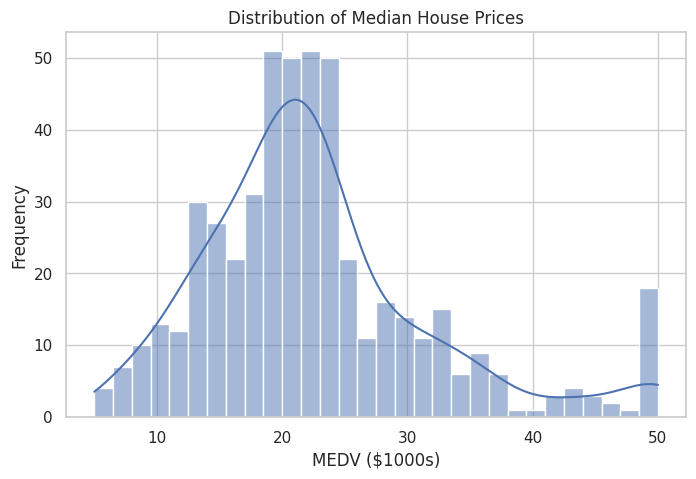

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(
    housing['MEDV'],
    bins=30,
    kde=True
)

plt.title('Distribution of Median House Prices')
plt.xlabel('MEDV ($1000s)')
plt.ylabel('Frequency')

plt.show()

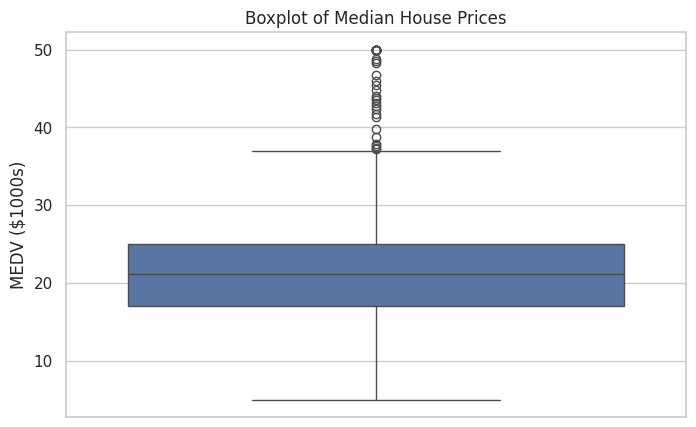

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=housing['MEDV'])

plt.title('Boxplot of Median House Prices')
plt.ylabel('MEDV ($1000s)')

plt.show()

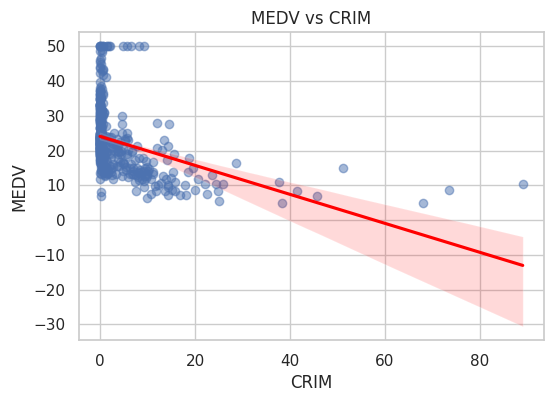

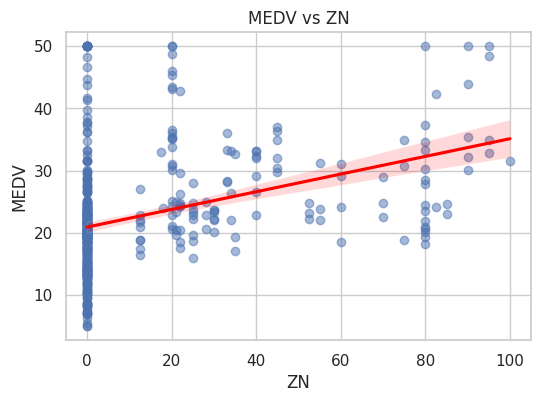

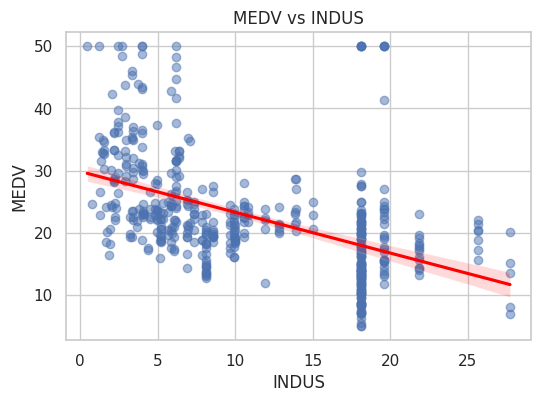

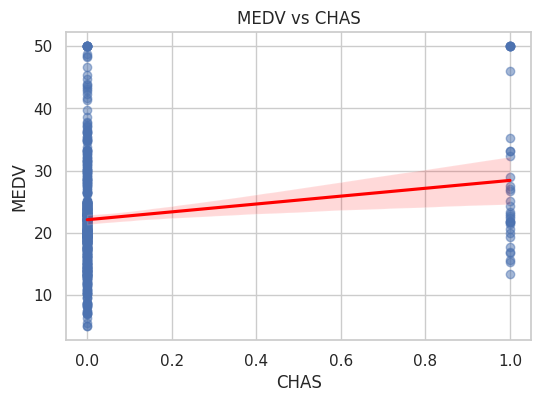

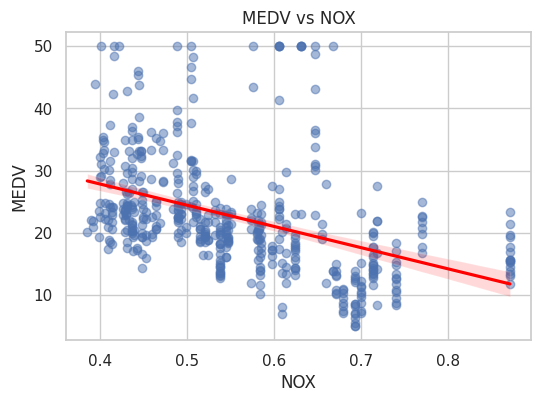

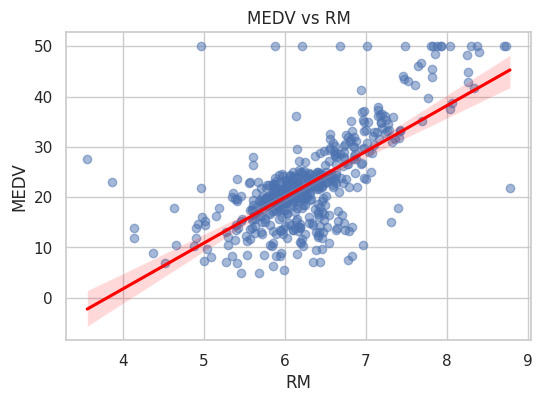

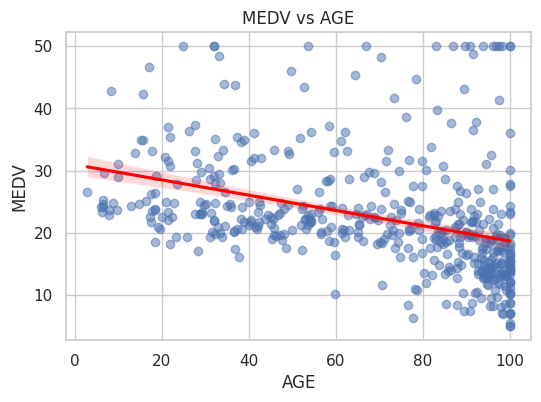

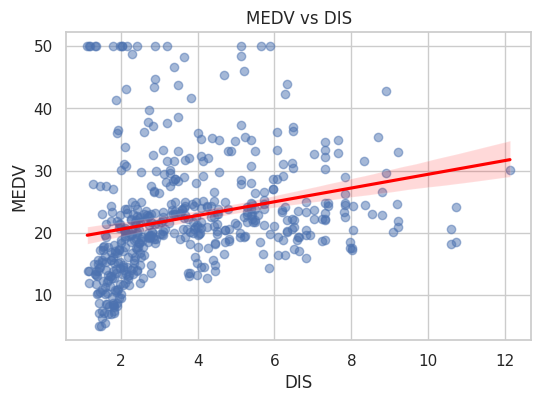

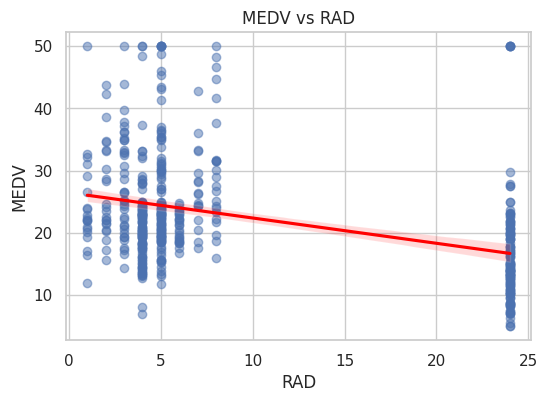

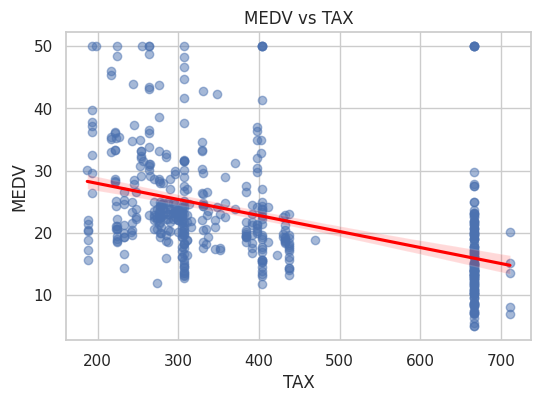

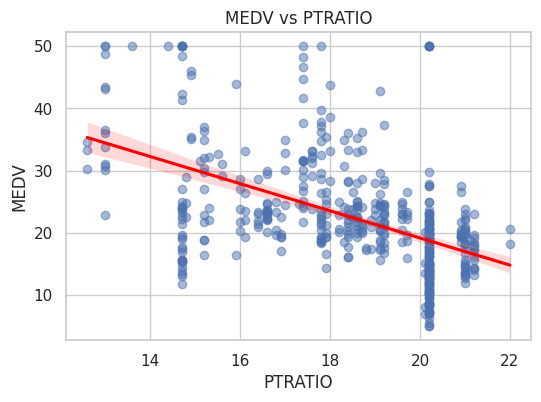

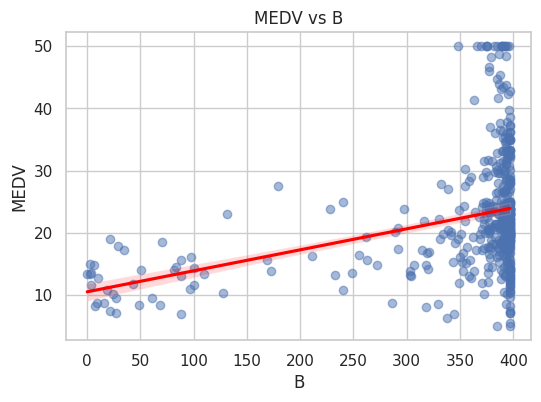

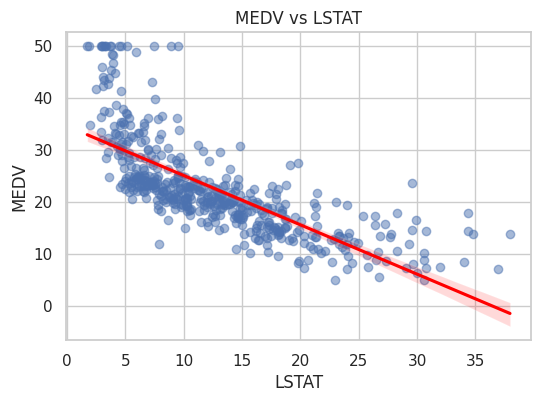

In [16]:
predictors = [
    col for col in housing.columns
    if col != 'MEDV'
]

for variable in predictors:

    plt.figure(figsize=(6, 4))

    sns.regplot(
        data=housing,
        x=variable,
        y='MEDV',
        scatter_kws={'alpha': 0.5},
        line_kws={'color': 'red'}
    )

    plt.title(f'MEDV vs {variable}')
    plt.show()